# Лабораторная работа № 2. Классификация изображений CIFAR-10

**Цель:** построить и обучить сверточную нейронную сеть на PyTorch, а затем оценить её на тестовой части CIFAR-10.

В наборе данных 10 классов: самолёт, автомобиль, птица, кошка, олень, собака, лягушка, лошадь, корабль и грузовик. Каждое изображение цветное, размером 32 × 32 пикселя. Используется стандартное разделение CIFAR-10: 50 000 обучающих и 10 000 тестовых изображений.

## 1. Импорт библиотек и настройки

In [12]:
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Фиксируем начальные состояния генераторов случайных чисел.
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство для вычислений: {device}")

Устройство для вычислений: cuda


## 2. Загрузка и подготовка данных

Изображение сначала переводится в тензор с порядком измерений `(каналы, высота, ширина)` и значениями от 0 до 1. Затем каждый цветовой канал нормализуется по формуле $x_{norm} = (x - mean) / std$. Используем средние значения и стандартные отклонения каналов обучающей части CIFAR-10.

Для обучающей выборки дополнительно применяем случайное горизонтальное отражение и случайное кадрирование с отступом в 4 пикселя. Это способы аугментации: они немного меняют изображение, сохраняя его класс, и помогают уменьшить переобучение. К тестовым данным случайные преобразования не применяются.

In [13]:
# Значения для RGB-каналов обучающей части CIFAR-10.
channel_mean = (0.4914, 0.4822, 0.4465)
channel_std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(channel_mean, channel_std),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(channel_mean, channel_std),
])

datasets.CIFAR10.url = (
    "https://huggingface.co/datasets/MIT-OL-AI-D/"
    "cifar-10-python/resolve/main/cifar-10-python.tar.gz"
)

train_dataset = datasets.CIFAR10(
    root="./data", train=True, download=True, transform=train_transform
)
test_dataset = datasets.CIFAR10(
    root="./data", train=False, download=True, transform=test_transform
)
class_names = train_dataset.classes

# Форма исходного массива: (число изображений, высота, ширина, каналы).
# Для одного элемента датасета изображение уже преобразовано в тензор.
example_image, example_label = train_dataset[0]

print("Обучающая выборка:", len(train_dataset))
print("Тестовая выборка:", len(test_dataset))

print("Форма обучающих изображений:", train_dataset.data.shape)
print("Форма тестовых изображений:", test_dataset.data.shape)

print("Форма обработанного изображения:", example_image.shape)

print("Форма обучающих меток:", np.asarray(train_dataset.targets).shape)
print("Форма тестовых меток:", np.asarray(test_dataset.targets).shape)

print("Пример метки:", example_label)
print("Название класса:", class_names[example_label])
print("Классы:", class_names)

Обучающая выборка: 50000
Тестовая выборка: 10000
Форма обучающих изображений: (50000, 32, 32, 3)
Форма тестовых изображений: (10000, 32, 32, 3)
Форма обработанного изображения: torch.Size([3, 32, 32])
Форма обучающих меток: (50000,)
Форма тестовых меток: (10000,)
Пример метки: 6
Название класса: frog
Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


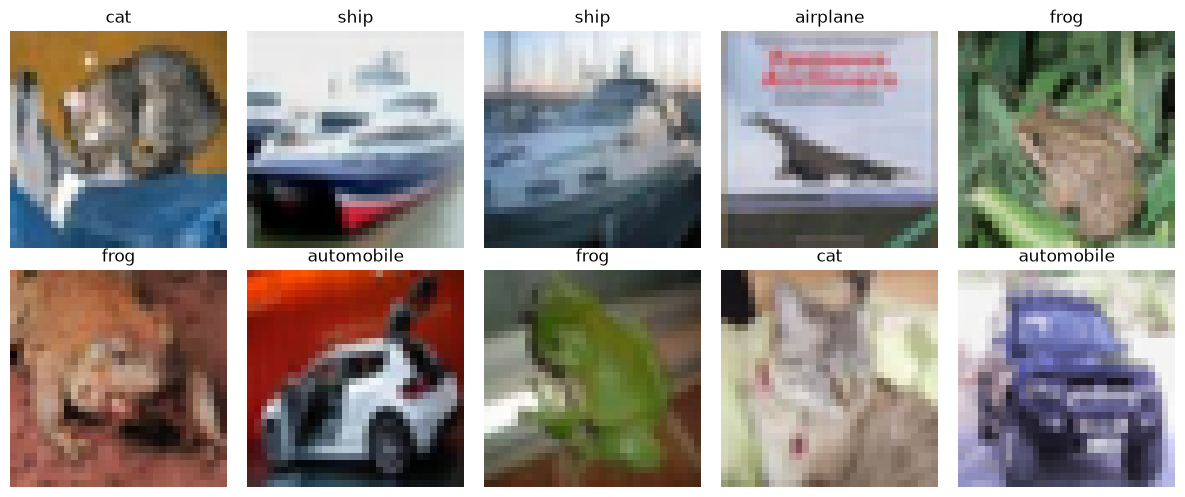

In [14]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
mean = torch.tensor(channel_mean).view(3, 1, 1)
std = torch.tensor(channel_std).view(3, 1, 1)

for index, ax in enumerate(axes.flat):
    image, label = test_dataset[index]
    image = image * std + mean  # возвращаем цвета к диапазону [0, 1]
    image = image.clamp(0, 1).permute(1, 2, 0)  # меняем порядок осей на (высота, ширина, каналы)
    ax.imshow(image.numpy())
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Сверточная сеть

In [15]:
class CIFAR10CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Вход: 3 × 32 × 32; после блока: 32 × 16 × 16.
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # После блока: 64 × 8 × 8.
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # После блока: 128 × 4 × 4.
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(p=0.4),
            nn.Linear(256, 10),
        )

    def forward(self, images):
        features = self.features(images)
        logits = self.classifier(features)
        return logits


model = CIFAR10CNN().to(device)
print(model)
print(f"Число обучаемых параметров: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

CIFAR10CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(64, 128, k

## 4. Параметры обучения и метрики

In [16]:
batch_size = 128
num_epochs = 30
learning_rate = 0.001
weight_decay = 0.0001 # регуляризация для предотвращения переобучения (убирает слишком большие веса)

train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, num_workers=0 # shuffle=True для перемешивания данных в каждой эпохе, num_workers=0 для использования основного процесса
)
test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False, num_workers=0
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs) # планировщик изменения скорости обучения

## 5. Обучение

Для каждой пачки выполняем прямой проход, вычисляем функцию потерь, обнуляем старые градиенты, выполняем обратное распространение и обновляем веса. Потери накапливаются с учётом размера пачки, поэтому последняя неполная пачка не искажает среднее. После каждой эпохи выводим потери, точность и долю ошибок на обучающей выборке.

In [17]:
train_losses = []
train_accuracies = []
train_errors = []

for epoch in range(num_epochs):
    model.train()  # включает обучение для BatchNorm и Dropout
    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_count = labels.size(0)
        total_loss += loss.item() * batch_count
        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_count

    epoch_loss = total_loss / total
    epoch_accuracy = 100.0 * correct / total
    epoch_error = 100.0 - epoch_accuracy
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)
    train_errors.append(epoch_error)
    scheduler.step()

    print(
        f"Эпоха {epoch + 1:2d}/{num_epochs}: "
        f"потери = {epoch_loss:.4f}, "
        f"точность = {epoch_accuracy:.2f}%, "
        f"ошибка классификации = {epoch_error:.2f}%"
    )

Эпоха  1/30: потери = 1.5184, точность = 43.31%, ошибка классификации = 56.69%
Эпоха  2/30: потери = 1.0577, точность = 62.12%, ошибка классификации = 37.88%
Эпоха  3/30: потери = 0.8966, точность = 68.69%, ошибка классификации = 31.31%
Эпоха  4/30: потери = 0.7940, точность = 72.67%, ошибка классификации = 27.33%
Эпоха  5/30: потери = 0.7271, точность = 74.86%, ошибка классификации = 25.14%
Эпоха  6/30: потери = 0.6729, точность = 77.14%, ошибка классификации = 22.86%
Эпоха  7/30: потери = 0.6189, точность = 79.20%, ошибка классификации = 20.80%
Эпоха  8/30: потери = 0.5817, точность = 80.30%, ошибка классификации = 19.70%
Эпоха  9/30: потери = 0.5477, точность = 81.58%, ошибка классификации = 18.42%
Эпоха 10/30: потери = 0.5174, точность = 82.37%, ошибка классификации = 17.63%
Эпоха 11/30: потери = 0.4859, точность = 83.71%, ошибка классификации = 16.29%
Эпоха 12/30: потери = 0.4686, точность = 84.26%, ошибка классификации = 15.74%
Эпоха 13/30: потери = 0.4389, точность = 85.26%, оши

## 6. Оценка на тестовой выборке

Вызываем `model.eval()` для того, чтобы Dropout отключился, а BatchNorm использовал накопленные при обучении статистики. В `torch.no_grad()` градиенты не вычисляются, потому что веса менять не нужно.

In [18]:
model.eval()
test_loss_sum = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        loss = criterion(logits, labels)
        predictions = logits.argmax(dim=1)

        batch_count = labels.size(0)
        test_loss_sum += loss.item() * batch_count
        test_correct += (predictions == labels).sum().item()
        test_total += batch_count

test_loss = test_loss_sum / test_total
test_accuracy = 100.0 * test_correct / test_total
test_error = 100.0 - test_accuracy

print(f"Тестовых изображений: {test_total}")
print(f"Средняя функция потерь: {test_loss:.4f}")
print(f"Точность на тестовой выборке: {test_accuracy:.2f}%")
print(f"Ошибка классификации на тестовой выборке: {test_error:.2f}%")

Тестовых изображений: 10000
Средняя функция потерь: 0.3580
Точность на тестовой выборке: 88.80%
Ошибка классификации на тестовой выборке: 11.20%


## 7. Изменение ошибки в процессе обучения

На первом графике показана доля неверных ответов в каждой эпохе, а на втором среднее значение функции потерь.

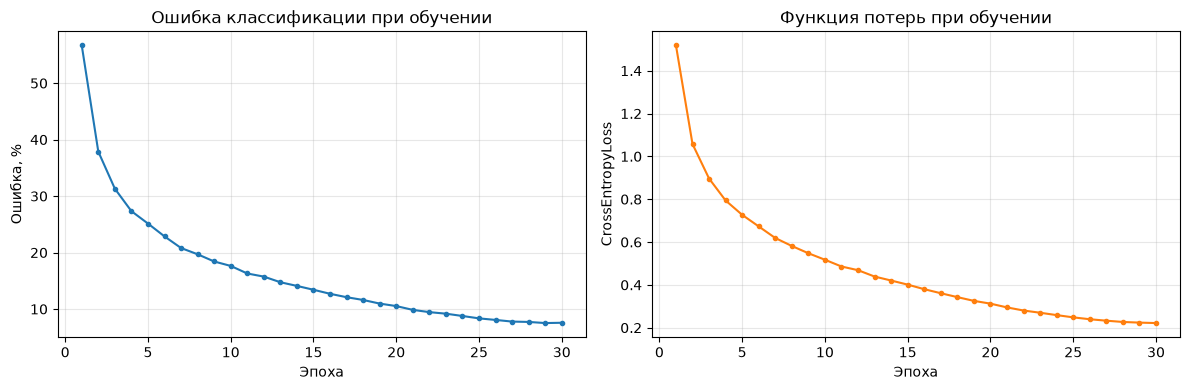

In [19]:
epochs = range(1, num_epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, train_errors, marker="o", markersize=3)
axes[0].set_title("Ошибка классификации при обучении")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Ошибка, %")
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs, train_losses, marker="o", markersize=3, color="tab:orange")
axes[1].set_title("Функция потерь при обучении")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("CrossEntropyLoss")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()